# Calibration of the SP mixture: French railway stations

Row `Gares France` of Table 1 of the paper and of `out/00_dataset_calibration_reference.csv`.
The chain is the one of Sec. 3.1, written once in `src/calibration.py`
(`scripts/calibrate_all.py` runs it on every dataset); this notebook calls its
functions step by step and explains the choices.

Common structure agreed with Charles (November 2026), which replaces the
original run of March 2026 (kept in git history):

1. **SP generation**: the N-dimensional generator `sp_helpers.soneira_peebles_nd`
   is used with `dim = 2`. The border is handled child by child (a child drawn
   outside the territory is redrawn around its parent), instead of redrawing the
   whole tree (`check_inside`, cost 1/p with p = 2–16 %) or truncating it at the
   border (former `build_sp_model`, now `build_sp_model_truncated`).
2. **Amplitude ratio**: log a = ⟨log ξ_data − log ξ_SP⟩ over the bins of the
   power-law fit window, instead of the ratio ρ = ⟨ξ_data / ξ_SP⟩.
3. **2PCF**: a single chain (`methods_two_point_correlation.PCF_with_variance`, in
   metres, random catalogues inside the border) and a single fit convention, with a **minimum-pairs
   criterion** on the small-r bins (`sp_helpers.fit_window`).

The random catalogues of the 2PCF are not seeded, so a new run gives slightly
different values (γ moves by about its fitted error).

## 0. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = Path("../../../").resolve()
sys.path.insert(0, str(root / "src"))

import calibration as cal
import synthesis_utils as su
from sp_helpers import power_law, _align, MIN_PAIRS, FIT_RANGE

name = "Gares France"
ds = su.DATASETS[name]
crs, rmax = ds["crs"], ds["rmax"]
print(f"{name}: {ds['path_csv'].name}  crs={crs}  rmax={rmax / 1e3:.0f} km")
print("2PCF parameters:", cal.PCF_PARAMS)
print(f"fit window: bins [{FIT_RANGE[0]}, {FIT_RANGE[1]}), MIN_PAIRS = {MIN_PAIRS}")

Gares France: noeuds_route500_gares.csv  crs=EPSG:2154  rmax=160 km
2PCF parameters: {'N_run': 5, 'size': 7000, 'k': 3, 'scale': 'log', 'nbins': 20, 'bootstrap_size': 10000, 'bootstrap_N_real': 10}
fit window: bins [1, 19), MIN_PAIRS = 100


## 1. Territory

Border in a metric CRS. The 2PCF chain of `methods_two_point_correlation` draws its
random catalogues in the border it is given, which has to be the territory of the
data. Here the border file is a multipolygon whose largest polygon is the mainland
(the Natural Earth border of France also holds Corsica and the overseas territories, 21 parts in all, whose common centroid is in the Atlantic), so the entry of
`DATASETS` sets `largest_only=True` and the mainland alone is the domain, as in
Table 1 (R_ref below). R_ref = 0.5 × perimeter / 2π is the
radius of the level-0 disc of the fractal and its seed is the centroid of the
territory.

In [2]:
gdf_edge, R_ref = cal.load_territory(ds)          # mainland: DATASETS sets largest_only=True
print(f"Polygons  : {len(gdf_edge.explode(index_parts=False))}")
print(f"Area      : {gdf_edge.area.sum() / 1e6:,.0f} km²")
print(f"Perimeter : {gdf_edge.length.sum() / 1e3:,.0f} km")
print(f"R_ref     : {R_ref / 1e3:.1f} km")

Polygons  : 1
Area      : 538,401 km²
Perimeter : 6,244 km
R_ref     : 496.9 km


## 2. Dataset

In [3]:
gdf_projected, coords, marks = cal.load_points(ds, gdf_edge)
N = len(coords)
print(f"N = {N:,} points inside the territory, mark = {ds['threshold_variable']}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
gdf_edge.plot(ax=ax, color="#e8f4f8", edgecolor="#2c5f8a", linewidth=1)
ax.scatter(coords[:, 0], coords[:, 1], s=0.4, alpha=0.3, color="steelblue")
ax.set_title(f"{name} (N={N:,})"); ax.axis("equal"); ax.set_xticks([]); ax.set_yticks([])
ax = axes[1]
pos = marks[marks > 0]
if len(pos):
    ax.hist(np.clip(pos, None, np.quantile(pos, 0.99)), bins=50,
            color="steelblue", edgecolor="white")
    ax.set_yscale("log"); ax.set_xlabel(ds["threshold_variable"]); ax.set_ylabel("count")
plt.tight_layout(); plt.show()

N = 3,470 points inside the territory, mark = population_density


<Figure size 1300x500 with 2 Axes>

## 3. Data 2PCF and γ_cal

Landy–Szalay estimator with split random catalogues (Keihänen et al. 2019):
5 catalogues of 7 000 points drawn in the territory, 20 logarithmic edges from the
mean nearest-neighbour distance to r_max, ξ attached to the upper edge of the bin
(`PCF_with_variance`). Below 10⁴ nodes the estimator is repeated k = 3 times with new
catalogues; above, it is computed on 10 random sub-samples of 10⁴ nodes.

**Fit window and minimum-pairs criterion** (`sp_helpers.fit_window`). The power law
ξ(r) = (r/r₀)^(−γ) is fitted by least squares weighted by the spread over the
repetitions, on the bins 1 to 18: bin 0 (d ≤ mean nearest-neighbour distance) and
the last bin (cut by r_max and by the border) are left out. In addition, the
**small-r bins that hold fewer than MIN_PAIRS = 100 data pairs are dropped**, up to
the first bin that reaches the threshold. The reason is statistical: ξ in a bin is
(DD − 2DR + RR)/RR, and with DD data pairs its Poisson noise is of relative size
1/√DD, i.e. 10 % at 100 pairs and 30 % at 10 pairs; with few pairs the estimator is
dominated by that noise, can be negative, and the σ-weighting does not protect the
fit because σ is estimated from k = 3 repetitions that share the same DD. The
criterion only moves the lower bound of the window (the bins above the first
accepted one all stay), and the same window is reused for the amplitude ratio
(section 8), so that γ and a are estimated on the same bins. **Mean over runs.** The random catalogues are drawn without a fixed seed, so γ moves
from one run of the 2PCF to the next (spread 0.01 to 0.13 on extracts of 3 000 nodes,
notebook 10), as much as the differences we want to read. γ_cal is therefore the mean
of the fits of `N_GAMMA_RUNS = 5` independent runs (`calibration.data_2pcf_runs`), each
run fitted on its own window; the spread of the runs is printed next to the fit error
of one run. ξ_data, used by the m-scan and by the amplitude ratio, is the mean over the
realisations of all the runs. The window shown is the one of the first run (below 10⁴
nodes the DD counts, hence the criterion, are the same in every run).

The table below shows
the DD count of every bin and whether it enters the fit.

γ_cal = 0.7303  (mean of 5 runs, spread 0.0419, fit error of one run 0.0637)   r₀ = 50.21 km   D = 2 − γ = 1.270
γ of each run: [0.6901 0.795  0.6967 0.7298 0.74  ]
fit window: bins 1..18 (5.42–132.6 km), 0 small-r bin(s) dropped by the minimum-pairs criterion (DD < 100): []


,r_upper_km,DD_pairs,xi,xi_std,in_fit
0,4.489,4200,4.857,0.049,False
1,5.418,1659,4.142,0.052,True
2,6.539,2384,4.090,0.054,True
3,7.892,3210,3.740,0.054,True
4,9.525,4490,3.587,0.033,True
5,11.496,6048,3.275,0.031,True
6,13.875,8080,2.966,0.027,True
7,16.747,10712,2.653,0.025,True
8,20.212,14401,2.417,0.019,True
9,24.395,17644,1.943,0.019,True


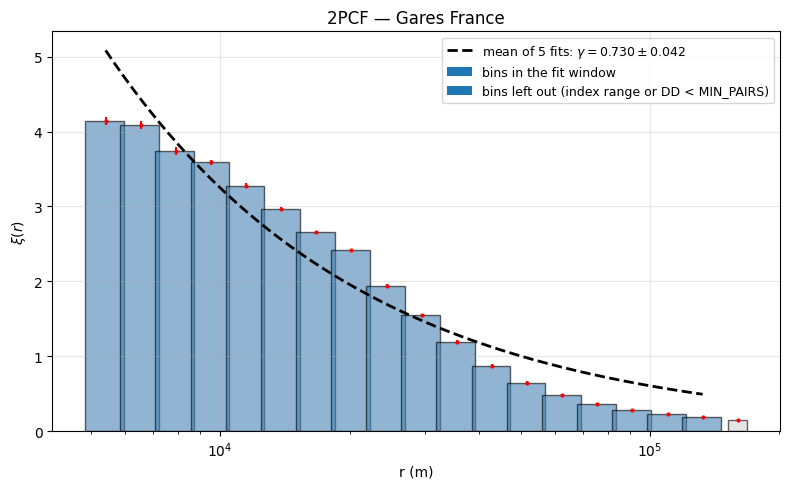

In [4]:
# N_GAMMA_RUNS = 5 independent runs of the 2PCF; gamma and r0 are the means of the fits
# of the runs, and the realisations of all the runs are stacked in l_xi
runs = cal.data_2pcf_runs(gdf_projected, gdf_edge, crs, rmax)
r_edges, l_xi, counts = runs["r_edges"], runs["l_xi"], runs["counts"]
gamma, r0, gamma_err, r0_err = runs["gamma"], runs["r0"], runs["gamma_err"], runs["r0_err"]
gamma_std, mask, win = runs["gamma_std"], runs["mask"], runs["win"]
xi_data = cal._xi_mean(r_edges, l_xi)
xi_std = np.nanstd(l_xi, axis=0)[:len(xi_data)]
dd = counts["DD"][:len(xi_data)]

print(f"γ_cal = {gamma:.4f}  (mean of {runs['n_ok']} runs, spread {gamma_std:.4f}, "
      f"fit error of one run {gamma_err:.4f})   r₀ = {r0 / 1e3:.2f} km   D = 2 − γ = {2 - gamma:.3f}")
print("γ of each run:", np.round(runs["gamma_runs"], 4))
print(f"fit window: bins {win['first']}..{win['last']} "
      f"({win['r_lo'] / 1e3:.2f}–{win['r_hi'] / 1e3:.1f} km), "
      f"{len(win['dropped_min_pairs'])} small-r bin(s) dropped by the "
      f"minimum-pairs criterion (DD < {win['min_pairs']}): {win['dropped_min_pairs']}")

table = pd.DataFrame({"r_upper_km": r_edges[:len(xi_data)] / 1e3,
                      "DD_pairs": dd.astype(int),
                      "xi": xi_data, "xi_std": xi_std,
                      "in_fit": mask})
display(table.round(3))

# Sort the data by decreasing mark for the m-scan
coords_sorted = coords[np.argsort(marks)[::-1]]

fig, ax = plt.subplots(figsize=(8, 5))
r_d, w_d = r_edges[1:len(xi_data)], np.diff(np.append(r_edges[1:len(xi_data)], 1.1 * r_edges[len(xi_data) - 1]))
colors = np.where(mask[1:], "steelblue", "lightgray")
ax.bar(r_d, xi_data[1:], width=w_d, align="center", edgecolor="black",
       color=colors, alpha=0.6)
ax.errorbar(r_d, xi_data[1:], yerr=xi_std[1:], fmt="o", color="red", ms=2)
ax.bar([], [], color="steelblue", label="bins in the fit window")
ax.bar([], [], color="lightgray", label="bins left out (index range or DD < MIN_PAIRS)")
r_fit = np.logspace(np.log10(win["r_lo"]), np.log10(win["r_hi"]), 200)
ax.plot(r_fit, power_law(r_fit, gamma, r0), "--", color="black", lw=2,
        label=rf"mean of {runs['n_ok']} fits: $\gamma = {gamma:.3f} \pm {gamma_std:.3f}$")
ax.set_xscale("log"); ax.set_xlabel("r (m)"); ax.set_ylabel(r"$\xi(r)$")
ax.set_title(f"2PCF — {name}"); ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 4. Branching factor η

η is the number of k-means clusters that maximises the silhouette score
(`calibration.silhouette_eta`, 3 sub-samples of 1 500 points per k).

η = 6  (silhouette 0.4722)


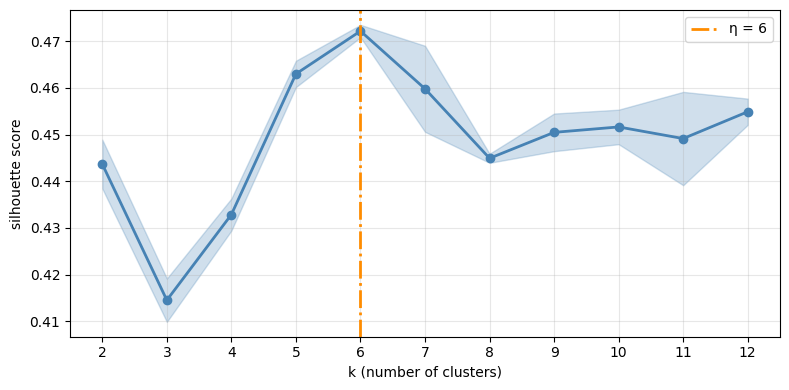

In [5]:
eta, k_values, sil_means, sil_stds = cal.silhouette_eta(coords)
print(f"η = {eta}  (silhouette {sil_means.max():.4f})")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_values, sil_means, "o-", color="steelblue", lw=2, ms=6)
ax.fill_between(k_values, sil_means - sil_stds, sil_means + sil_stds, alpha=0.25, color="steelblue")
ax.axvline(eta, color="darkorange", lw=2, ls="-.", label=f"η = {eta}")
ax.set_xlabel("k (number of clusters)"); ax.set_ylabel("silhouette score")
ax.set_xticks(k_values); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 5. m-scan

The m nodes of largest mark form A, the others form B. The cross-2PCF follows from
the 2PCFs of the data, of A and of B,

$$\xi_{AB}(r) = \frac{N^2\,\xi_{\rm data}(r) - m^2\,\xi_{AA}(r) - (N-m)^2\,\xi_{BB}(r)}{2\,m\,(N-m)},$$

and m* minimises ∫|ξ_AB(r)| dr over 40 values of m between N/20 and N − N/20
(`calibration.m_scan`, in parallel). When A holds the structured part and B a
background, ξ_AB is close to zero. The sub-2PCFs use the same chain with the
lighter settings of `calibration.pcf_budget` above 5 000 points.

m-scan:   0%|          | 0/40 [00:00<?, ?it/s]

m-scan:  30%|███       | 12/40 [00:24<00:56,  2.01s/it]

m-scan:  45%|████▌     | 18/40 [00:58<01:18,  3.55s/it]

m-scan:  60%|██████    | 24/40 [01:22<00:59,  3.71s/it]

m-scan:  75%|███████▌  | 30/40 [01:46<00:37,  3.80s/it]

m-scan:  90%|█████████ | 36/40 [02:10<00:15,  3.88s/it]

m-scan: 100%|██████████| 40/40 [02:10<00:00,  3.26s/it]

m* = 3,136   (m*/N = 0.904, integral 36816.3459)


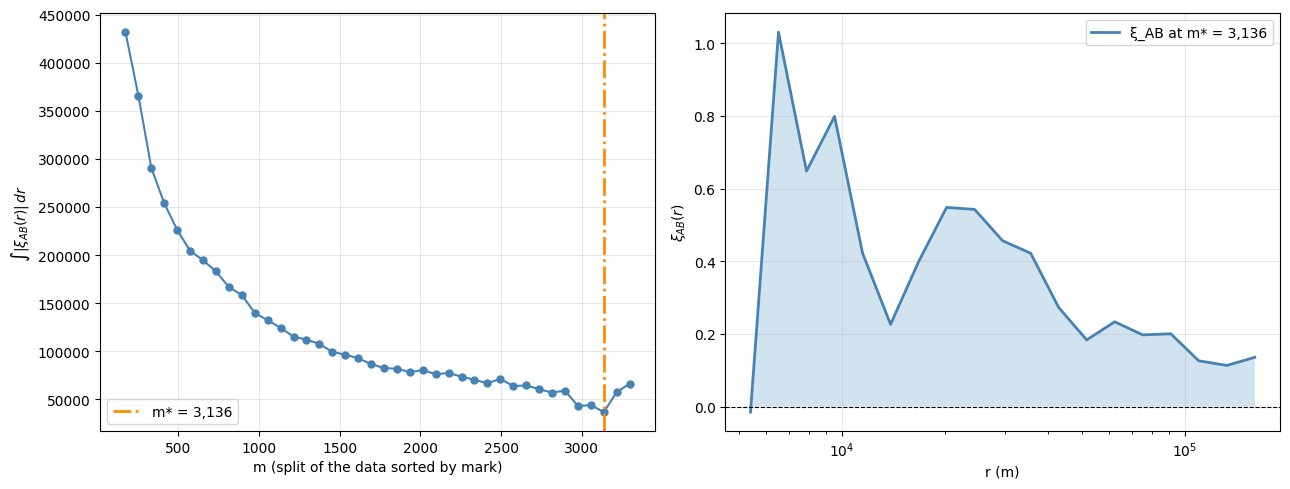

In [6]:
m_arr, int_arr, scan = cal.m_scan(coords_sorted, xi_data, r_edges, gdf_edge, crs,
                                  rmax, n_scan=40, n_jobs=6)
m_star, i_star = cal.find_m_star(m_arr, int_arr)
print(f"m* = {m_star:,}   (m*/N = {m_star / N:.3f}, integral {int_arr[i_star]:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
ax.plot(m_arr, int_arr, "o-", color="steelblue", lw=1.5, ms=5)
ax.axvline(m_star, color="darkorange", lw=2, ls="-.", label=f"m* = {m_star:,}")
ax.set_xlabel("m (split of the data sorted by mark)"); ax.set_ylabel(r"$\int|\xi_{AB}(r)|\,dr$")
ax.legend(); ax.grid(alpha=0.3)
ax = axes[1]
r_c, xi_c = scan[i_star]["r_edges"], scan[i_star]["xi"]
ax.plot(r_c[1:], xi_c[1:], color="steelblue", lw=2, label=f"ξ_AB at m* = {m_star:,}")
ax.fill_between(r_c[1:], 0, xi_c[1:], alpha=0.2); ax.axhline(0, color="black", lw=0.8, ls="--")
ax.set_xscale("log"); ax.set_xlabel("r (m)"); ax.set_ylabel(r"$\xi_{AB}(r)$")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6. SP fractal (N-dimensional generator, dim = 2)

λ = η^(1/(dim − γ_cal)) with dim = 2 (`sp_helpers.lambda_of_gamma`), radius R_ref,
seed at the centroid of the territory, L the smallest depth with η^L ≥ m*
(`calibration.build_sp`, which calls `sp_helpers.build_sp_model` with `dim=2` and a
seeded generator). The children of a node are drawn uniformly in the disc of radius
R_ref / λ^i (`radial="uniform"`, the definition of Soneira & Peebles; the historical
2D code drew the radius linearly, which concentrates the children towards the
centre).

Border: every child drawn outside the territory is redrawn around its parent (up
to 64 times), so all the η^L leaves are inside, the tree keeps its exact size and
is not biased towards the centre of the territory. The previous version truncated
the tree at the border and raised L until enough leaves remained inside, which
loses the outer branches; the original `check_inside` redrew the whole tree as long
as one leaf was outside, which does not converge for large trees.

In [7]:
pos_sp, L_sp, lamb_sp = cal.build_sp(m_star, eta, gamma, R_ref, gdf_edge, crs, seed=42)
m_sp = len(pos_sp)
print(f"SP: η={eta}  λ={lamb_sp:.3f}  L={L_sp}  m_SP={m_sp:,} = η^L nodes, all inside "
      f"(target m*={m_star:,})")

SP: η=6  λ=4.101  L=5  m_SP=7,776 = η^L nodes, all inside (target m*=3,136)


## 7. Slope of the fractal

The slope of the complete fractal should be close to γ_cal. Eq. (1) of the paper
holds for the average over realisations, so one realisation can differ by a few
tenths. Same 2PCF chain and same fit window rules (the minimum-pairs criterion is
applied to the DD counts of the SP points).
As for the data, γ_SP is the mean of the fits of 5 runs of the 2PCF of the same
SP draw (`calibration.sp_2pcf_runs`).

**Spread of γ_SP.** The criterion counts the DD pairs only. When the SP clumps are
much smaller than the spacing of the random catalogue (η = 6 on RTE France and Gares
France), the first bins hold 1 to 10 RR pairs, ξ_SP there is set by the noise of RR,
and γ_SP moves by up to ±0.5 from one run to the next (spread 0.53 and 0.47 on these
two datasets, 0.03 or less elsewhere). γ_SP is a check only: it does not enter
`DATASETS`. A criterion on min(DD, RR) would remove these bins (open question,
November 2026).

data γ = 0.7303 ± 0.0419  (mean and spread of 5 runs)
SP   γ = 0.9153 ± 0.4706  (mean and spread of 5 runs)   (window bins 1..18, 0 dropped by the criterion)


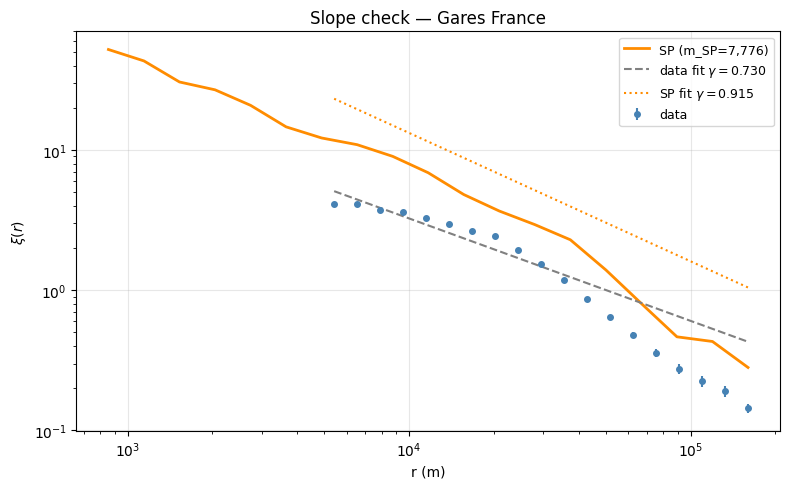

In [8]:
runs_sp = cal.sp_2pcf_runs(pos_sp, gdf_edge, crs, rmax)       # N_GAMMA_RUNS runs, as for the data
r_e_sp, l_xi_sp, counts_sp = runs_sp["r_edges"], runs_sp["l_xi"], runs_sp["counts"]
xi_sp = cal._xi_mean(r_e_sp, l_xi_sp)
r_e_sp = r_e_sp[:len(xi_sp)]
gamma_sp, r0_sp, gamma_sp_err = runs_sp["gamma"], runs_sp["r0"], runs_sp["gamma_err"]
gamma_sp_std, mask_sp, win_sp = runs_sp["gamma_std"], runs_sp["mask"], runs_sp["win"]
print(f"data γ = {gamma:.4f} ± {gamma_std:.4f}  (mean and spread of {runs['n_ok']} runs)")
print(f"SP   γ = {gamma_sp:.4f} ± {gamma_sp_std:.4f}  (mean and spread of {runs_sp['n_ok']} runs)   "
      f"(window bins {win_sp['first']}..{win_sp['last']}, "
      f"{len(win_sp['dropped_min_pairs'])} dropped by the criterion)")

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(r_edges[1:len(xi_data)], xi_data[1:], yerr=xi_std[1:], fmt="o", color="steelblue",
            ms=4, label="data")
ax.plot(r_e_sp[1:], xi_sp[1:], color="darkorange", lw=2, label=f"SP (m_SP={m_sp:,})")
r_fit = np.logspace(np.log10(r_edges[1]), np.log10(r_edges[len(xi_data) - 1]), 200)
ax.plot(r_fit, power_law(r_fit, gamma, r0), "--", color="gray", label=rf"data fit $\gamma={gamma:.3f}$")
ax.plot(r_fit, power_law(r_fit, gamma_sp, r0_sp), ":", color="darkorange", label=rf"SP fit $\gamma={gamma_sp:.3f}$")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("r (m)"); ax.set_ylabel(r"$\xi(r)$")
ax.set_title(f"Slope check — {name}"); ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 8. Dilution: amplitude ratio estimated in log

The mixture model says ξ_data(r) ≈ a ξ_SP(r), so the difference of the logs is
constant and log a is estimated as its mean over the fit window of section 3,

$$\log a = \left\langle \log \xi_{\rm data} - \log \xi_{\rm SP} \right\rangle_{\rm window,\ \xi_{\rm data}>0,\ \xi_{\rm SP}>0}$$

(`sp_helpers.log_amplitude_ratio`, ξ_SP interpolated on the data bins). Why a log
estimate rather than the former ratio ρ = ⟨ξ_data / ξ_SP⟩ (or α = 1/⟨|ξ_SP/ξ_data|⟩):
it is symmetric (a factor 2 too high and a factor 2 too low weigh the same, which a
ratio does not do, and this is what separated α and ρ), robust (a bin where one ξ is
almost zero no longer blows up the mean; ρ went from −0.03 to 2.3 over ten SP draws
on Belgium) and consistent (γ and a are estimated on the same bins).

Since ξ_mix = (m_SP / (m_SP + n_rand))² ξ_SP, adding n_rand = m_SP (a^(−1/2) − 1)
uniform points scales the 2PCF by a (`sp_helpers.dilution_from_a`; n_rand = 0 when
a ≥ 1).

log a = -0.706  →  a = 0.4937   (18 bins with ξ_data > 0 and ξ_SP > 0)
m_SP = 7,776   n_rand = 3,291   mixture = 11,067  →  delete 7,597 down to N = 3,470


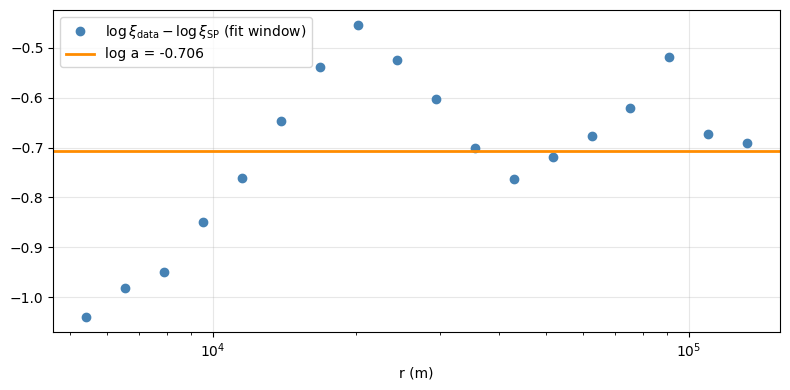

In [9]:
a, n_rand, dil = cal.dilution(xi_data, r_edges, xi_sp, r_e_sp, m_sp, mask)
print(f"log a = {dil['log_a']:.3f}  →  a = {a:.4f}   ({dil['n_bins']} bins with ξ_data > 0 and ξ_SP > 0)")
print(f"m_SP = {m_sp:,}   n_rand = {n_rand:,}   mixture = {m_sp + n_rand:,}  →  delete {max(0, m_sp + n_rand - N):,} down to N = {N:,}")

xi_sp_al = _align(r_e_sp, xi_sp, r_edges)
ok = mask & (xi_data > 0) & (xi_sp_al > 0)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(r_edges[ok], np.log(xi_data[ok]) - np.log(xi_sp_al[ok]), "o", color="steelblue",
        label=r"$\log \xi_{\rm data} - \log \xi_{\rm SP}$ (fit window)")
ax.axhline(dil["log_a"], color="darkorange", lw=2, label=f"log a = {dil['log_a']:.3f}")
ax.set_xscale("log"); ax.set_xlabel("r (m)"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

pos_mix, labels = cal.build_mixture(pos_sp, n_rand, gdf_edge, crs)

## 9. Final mixture

SP and uniform points are deleted at random down to N nodes. The deletion is
repeated over 5 realisations (mean ± std of the 2PCF). Figure: data, one
realisation, m-scan, 2PCF.

final: 3,470 points (2,425 SP, 1,045 random)


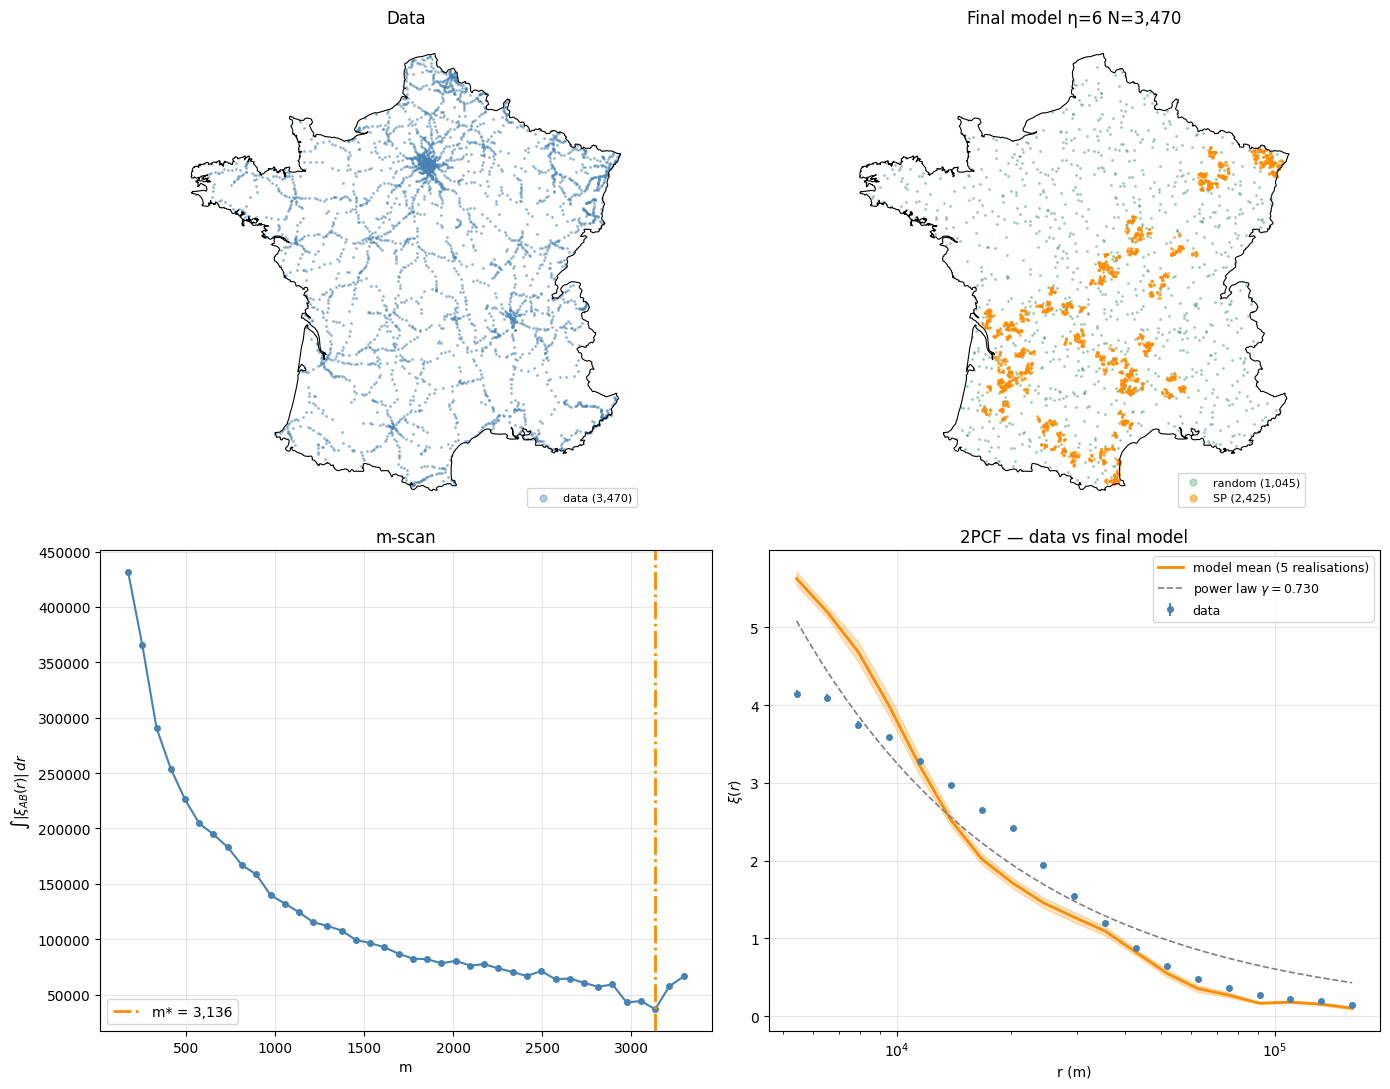

In [10]:
xi_f_mean, xi_f_std, pos_f, lab_f = cal.final_realisations(
    pos_mix, labels, N, gdf_edge, crs, r_edges, rmax, n_real=5)
n_sp_final = int((lab_f == 0).sum())
print(f"final: {len(pos_f):,} points ({n_sp_final:,} SP, {len(pos_f) - n_sp_final:,} random)")

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
ax = axes[0, 0]
gdf_edge.boundary.plot(ax=ax, color="black", lw=0.8)
ax.scatter(coords[:, 0], coords[:, 1], s=1.5, color="steelblue", alpha=0.4, label=f"data ({N:,})")
ax.set_title("Data"); ax.axis("off"); ax.legend(fontsize=8, markerscale=4, loc="lower right")
ax = axes[0, 1]
gdf_edge.boundary.plot(ax=ax, color="black", lw=0.8)
ax.scatter(*pos_f[lab_f == 1].T, s=1.5, color="seagreen", alpha=0.3, label=f"random ({len(pos_f) - n_sp_final:,})")
ax.scatter(*pos_f[lab_f == 0].T, s=1.5, color="darkorange", alpha=0.5, label=f"SP ({n_sp_final:,})")
ax.set_title(f"Final model η={eta} N={len(pos_f):,}"); ax.axis("off"); ax.legend(fontsize=8, markerscale=4, loc="lower right")
ax = axes[1, 0]
ax.plot(m_arr, int_arr, "o-", color="steelblue", lw=1.5, ms=4)
ax.axvline(m_star, color="darkorange", lw=2, ls="-.", label=f"m* = {m_star:,}")
ax.set_xlabel("m"); ax.set_ylabel(r"$\int|\xi_{AB}(r)|\,dr$"); ax.set_title("m-scan"); ax.legend(); ax.grid(alpha=0.3)
ax = axes[1, 1]
n = len(xi_data)
ax.errorbar(r_edges[1:n], xi_data[1:], yerr=xi_std[1:], fmt="o", color="steelblue", ms=4, label="data")
ax.plot(r_edges[1:n], xi_f_mean[1:n], color="darkorange", lw=2, label="model mean (5 realisations)")
ax.fill_between(r_edges[1:n], (xi_f_mean - xi_f_std)[1:n], (xi_f_mean + xi_f_std)[1:n], color="darkorange", alpha=0.25)
ax.plot(r_fit, power_law(r_fit, gamma, r0), "--", color="gray", lw=1.2, label=rf"power law $\gamma={gamma:.3f}$")
ax.set_xscale("log"); ax.set_xlabel("r (m)"); ax.set_ylabel(r"$\xi(r)$"); ax.set_title("2PCF — data vs final model")
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 10. Summary

Row of the calibration table (same keys as `calibration.SUMMARY_KEYS`), written to
`out/00_dataset_calibration.csv` (common chain, `calibration.update_summary_csv`) and
shown next to Table 1 of March 2026 (`out/00_dataset_calibration_reference.csv`, former
chain: truncated SP, ratio ρ, no minimum-pairs criterion, γ from one run).

In [11]:
row = dict(name=name, N=N, R_ref_m=R_ref, rmax=rmax, gamma=gamma, gamma_std=gamma_std,
           gamma_err=gamma_err, n_gamma_runs=runs["n_ok"], r0_m=r0, r0_err_m=r0_err, fit_first_bin=win["first"], fit_last_bin=win["last"],
           fit_r_lo_m=win["r_lo"], fit_r_hi_m=win["r_hi"],
           bins_dropped_min_pairs=len(win["dropped_min_pairs"]),
           eta=eta, silhouette=float(sil_means.max()), m_min=int(m_arr.min()),
           m_max=int(m_arr.max()), m_star=m_star, lamb=lamb_sp, L=L_sp, m_SP=m_sp,
           gamma_SP=gamma_sp, gamma_SP_std=gamma_sp_std, gamma_SP_err=gamma_sp_err, a=a, log_a=dil["log_a"],
           n_rand=n_rand, final_SP=n_sp_final, final_random=len(pos_f) - n_sp_final)
row["area_km2"] = float(gdf_edge.area.sum() / 1e6)
cal.update_summary_csv(row)          # row of out/00_dataset_calibration.csv (common chain)
ref = pd.read_csv(root / "out" / "00_dataset_calibration_reference.csv").set_index("name")
cmp = pd.DataFrame({"this run": pd.Series(row), "Table 1 (March 2026)": ref.loc[name]})
display(cmp)

,this run,Table 1 (March 2026)
L,5,5
N,3470,3470
R_ref_m,496882.852502,496900
a,0.49373,NaN
area_km2,538400.708439,538401
bins_dropped_min_pairs,0,NaN
eta,6,6
final_SP,2425,1806
final_random,1045,1664
fit_first_bin,1,NaN
